# Matplotlib

In [2]:
import matplotlib.pyplot as plt

### Basic charts

![](https://res.cloudinary.com/codecrucks/image/upload/c_scale,w_700,h_327,dpr_2/f_webp,q_auto/v1648958444/chart-types.png?_i=AA)

### Chart selection roadmap

![](http://blog.atkcg.ru/wp-content/uploads/2015/07/1-%D0%B9-%D1%81%D0%BB%D0%B0%D0%B9%D0%B41.jpg)

Из чего состоит график:

![image.png](https://matplotlib.org/stable/_images/sphx_glr_anatomy_001.png)

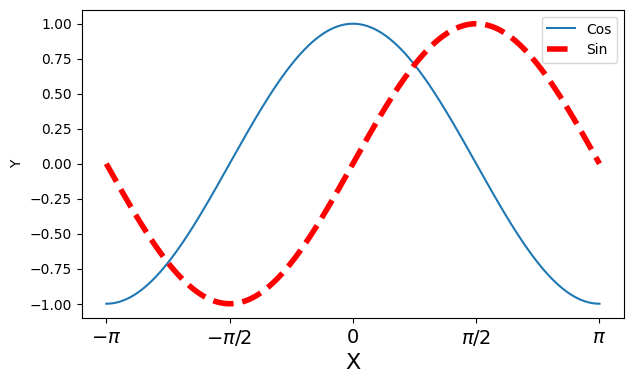

In [3]:
import numpy as np

plt.figure(figsize=(7, 4))
X = np.linspace(-np.pi, np.pi, 1000)
C, S = np.cos(X), np.sin(X)

plt.plot(X, C, label='Cos')
plt.plot(X, S, label='Sin', c='r', linestyle='--', linewidth=4)
plt.xlabel('X', fontsize=16)
plt.ylabel('Y')
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', 0, r'$\pi/2$', r'$\pi$'], fontsize=14)
plt.legend()
plt.show()

## Bonus

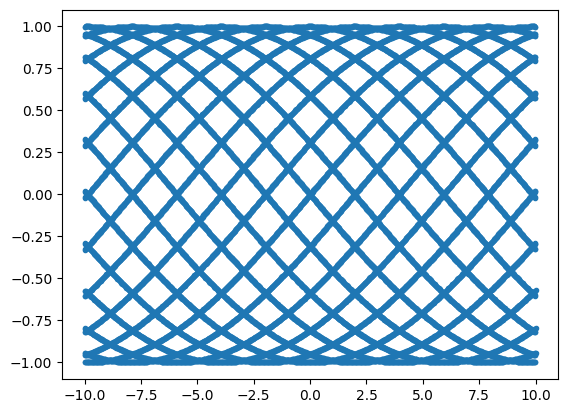

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-10, 10, 0.001) #set x=0.01, x=0.001 and see what happens
y = np.sin(314*x)

plt.plot(x,y, marker='.', linestyle='none')
plt.show()

# Homework

The data in [populations.txt](https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt) describes the populations of hares, lynxes and carrots in northern Canada during 20 years. Get the data with ```np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')``` and do the following exercises **without for-loops**.


Plot the population size of each species for each year on a single graph. Add legend and axis labels to the plot.

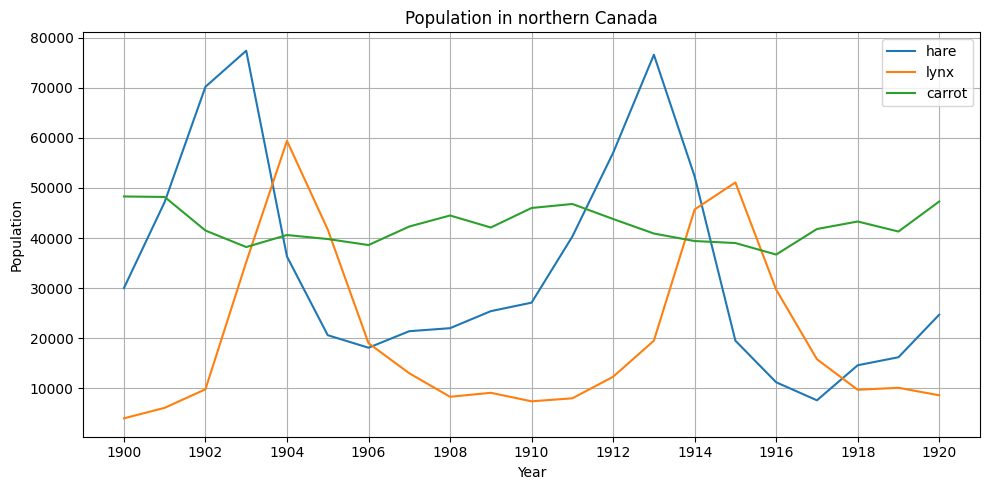

In [5]:
from io import StringIO

data = np.loadtxt(StringIO('# year\thare\tlynx\tcarrot\n1900\t30e3\t4e3\t48300\n1901\t47.2e3\t6.1e3\t48200\n1902\t70.2e3\t9.8e3\t41500\n1903\t77.4e3\t35.2e3\t38200\n1904\t36.3e3\t59.4e3\t40600\n1905\t20.6e3\t41.7e3\t39800\n1906\t18.1e3\t19e3\t38600\n1907\t21.4e3\t13e3\t42300\n1908\t22e3\t8.3e3\t44500\n1909\t25.4e3\t9.1e3\t42100\n1910\t27.1e3\t7.4e3\t46000\n1911\t40.3e3\t8e3\t46800\n1912\t57e3\t12.3e3\t43800\n1913\t76.6e3\t19.5e3\t40900\n1914\t52.3e3\t45.7e3\t39400\n1915\t19.5e3\t51.1e3\t39000\n1916\t11.2e3\t29.7e3\t36700\n1917\t7.6e3\t15.8e3\t41800\n1918\t14.6e3\t9.7e3\t43300\n1919\t16.2e3\t10.1e3\t41300\n1920\t24.7e3\t8.6e3\t47300\n'))
years = data[:, 0].astype(int)
populations = data[:, 1:]
species = np.array(['hare', 'lynx', 'carrot'])
colors = ['tab:blue', 'tab:orange', 'tab:green']
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True})

fig, ax = plt.subplots()
ax.plot(years, populations)
ax.set(xlabel='Year', ylabel='Population', title='Population in northern Canada')
ax.set_xticks(years[::2])
ax.legend(species)
plt.tight_layout()
plt.show()

Find which year each species had the largest population. Mark these years in the plot of populations.

Species: ['hare' 'lynx' 'carrot']
Max Years: [1903 1904 1900]
Max values: [77400. 59400. 48300.]


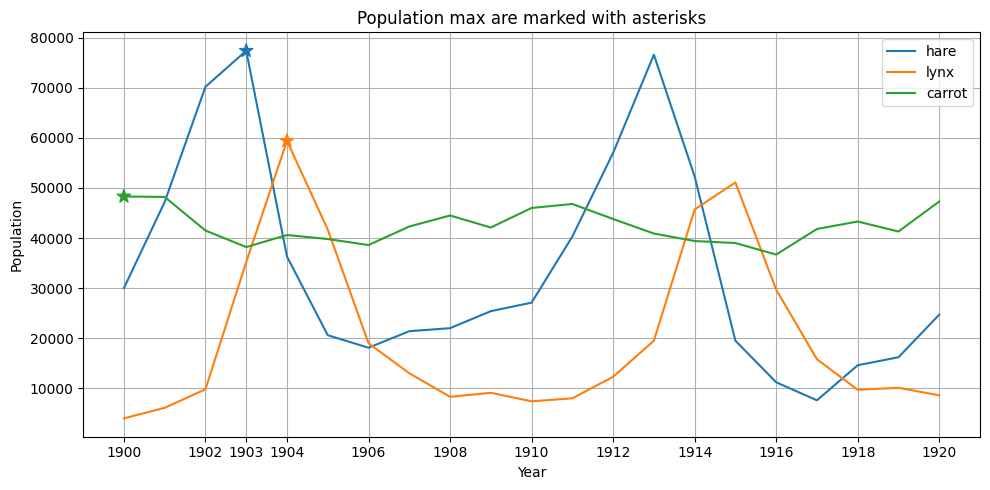

In [6]:
max_indices = populations.argmax(axis=0)
max_years = years[max_indices]
max_values = populations[max_indices, np.arange(3)]
print('Species:', species)
print('Max Years:', max_years)
print('Max values:', max_values)

fig, ax = plt.subplots()
ax.plot(years, populations)
ax.scatter(max_years, max_values, c=colors, s=100, marker='*', zorder=5)
ax.set(xlabel='Year', ylabel='Population', title='Population max are marked with asterisks')
ax.set_xticks(np.unique(np.r_[years[::2], max_years]))
ax.legend(species)
plt.tight_layout()
plt.show()

Assuming total population of hares and lynxes is 100%, plot stacked bar graph showing ratio of each specis for each year in the period.

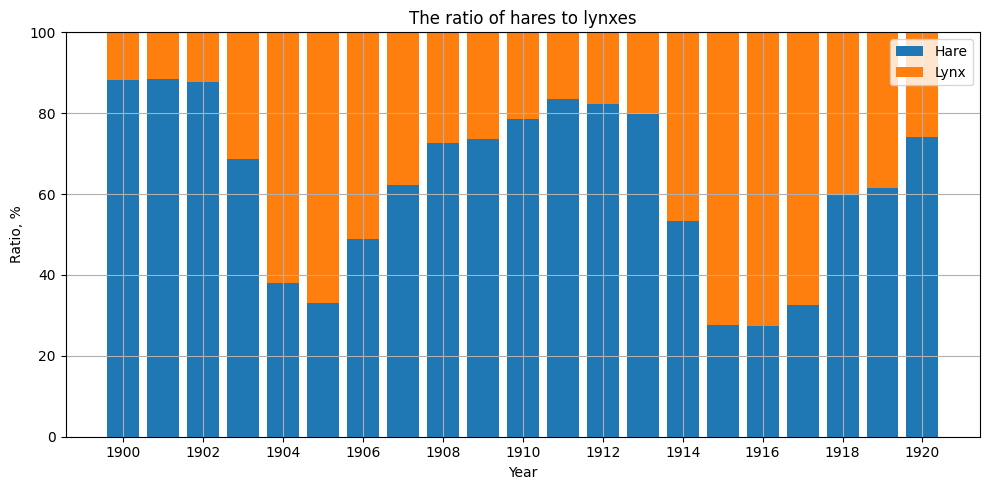

In [7]:
shares = populations[:, :2] / populations[:, :2].sum(axis=1, keepdims=True)
fig, ax = plt.subplots()
ax.bar(years, shares[:, 0] * 100, label='Hare')
ax.bar(years, shares[:, 1] * 100, bottom=shares[:, 0] * 100, label='Lynx')
ax.set(xlabel='Year', ylabel='Ratio, %', ylim=(0, 100), title='The ratio of hares to lynxes')
ax.set_xticks(years[::2])
ax.legend()
plt.tight_layout()
plt.show()

Find the mean and std of the populations of each species. Plot the historgam of population for each species and show mean values with vertical line. Show each histogram in a separate plot. Arrange 3 plots in a row.

Species: ['hare' 'lynx' 'carrot']
Mean: [34080.95 20166.67 42400.  ]
Standart deviation: [20897.91 16254.59  3322.51]


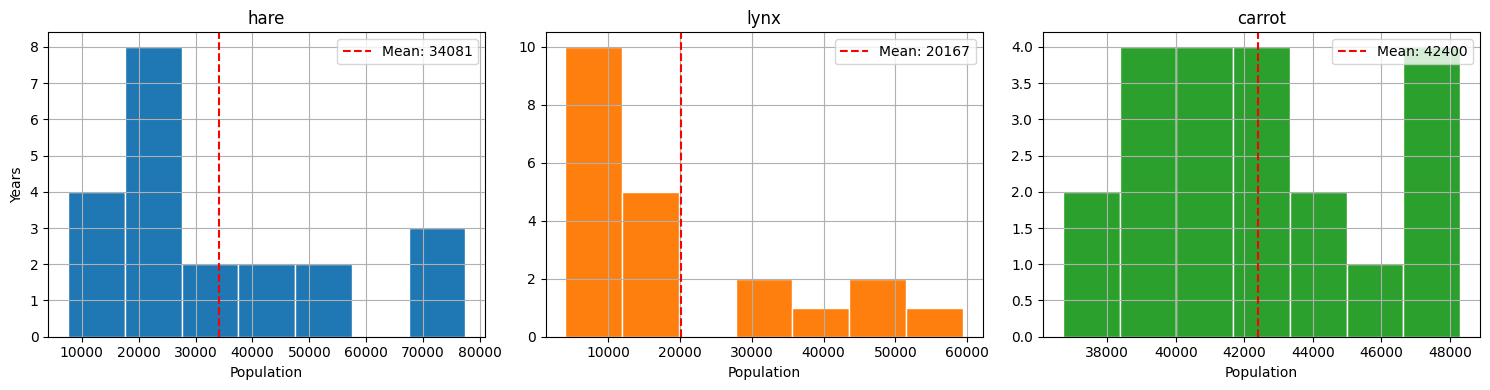

In [8]:
means = populations.mean(axis=0)
stds = populations.std(axis=0)
print('Species:', species)
print('Mean:', np.round(means, 2))
print('Standart deviation:', np.round(stds, 2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(populations[:, 0], bins=7, color=colors[0], edgecolor='white')
axes[1].hist(populations[:, 1], bins=7, color=colors[1], edgecolor='white')
axes[2].hist(populations[:, 2], bins=7, color=colors[2], edgecolor='white')
axes[0].axvline(means[0], color='red', linestyle='--', label=f'Mean: {means[0]:.0f}')
axes[1].axvline(means[1], color='red', linestyle='--', label=f'Mean: {means[1]:.0f}')
axes[2].axvline(means[2], color='red', linestyle='--', label=f'Mean: {means[2]:.0f}')
axes[0].set(title=species[0], xlabel='Population', ylabel='Years')
axes[1].set(title=species[1], xlabel='Population')
axes[2].set(title=species[2], xlabel='Population')
axes[0].legend()
axes[1].legend()
axes[2].legend()
plt.tight_layout()
plt.show()

Find which species (hares or lynxes) has the largest population for each year. Print the result as [H, H, L, H, ...]. Plot a pie chart showing the ratio of "H" and "L" values.

[H, H, H, H, L, L, L, H, H, H, H, H, H, H, H, L, L, L, H, H, H]
Years: [1900 1901 1902 1903 1904 1905 1906 1907 1908 1909 1910 1911 1912 1913
 1914 1915 1916 1917 1918 1919 1920]


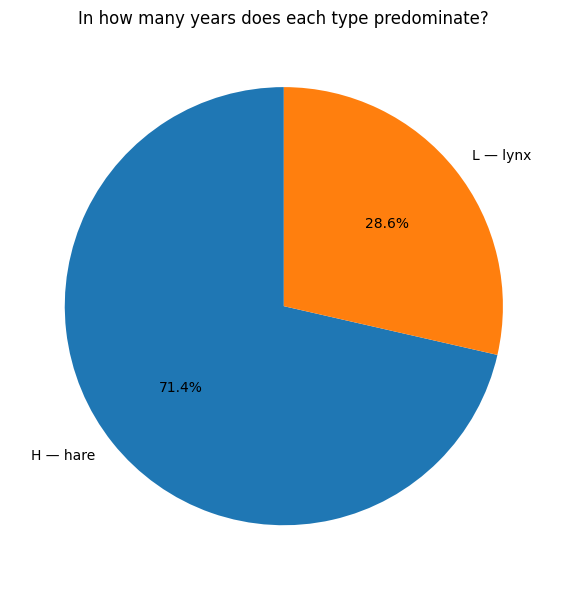

In [9]:
winners = np.where(populations[:, 0] >= populations[:, 1], 'H', 'L')
print('[' + ', '.join(winners.tolist()) + ']')
print('Years:', years)
counts = np.array([(winners == 'H').sum(), (winners == 'L').sum()])
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(counts, labels=['H — hare', 'L — lynx'], autopct='%1.1f%%', startangle=90)
ax.set_title('In how many years does each type predominate?')
plt.tight_layout()
plt.show()

Plot the change in the hare population and in the lynx population for each year. Find the correlation coefficient between the both time series.

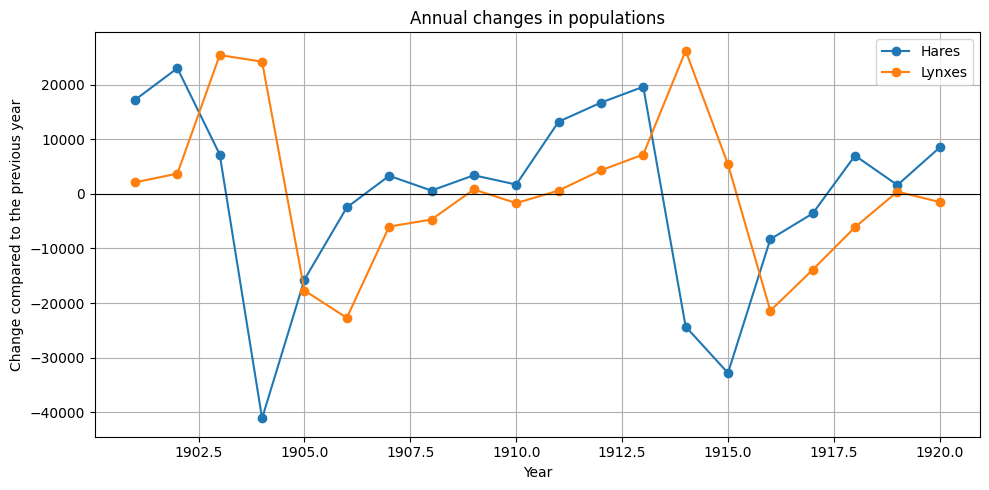

Correlation of population: 0.07189206073535571
Correlation of annual changes: -0.1780136594118296


In [10]:
changes = np.diff(populations[:, :2], axis=0)
fig, ax = plt.subplots()
ax.plot(years[1:], changes, marker='o')
ax.axhline(0, color='black', linewidth=0.8)
ax.set(xlabel='Year', ylabel='Change compared to the previous year', title='Annual changes in populations')
ax.legend(['Hares', 'Lynxes'])
plt.tight_layout()
plt.show()
print('Correlation of population:', np.corrcoef(populations[:, :2], rowvar=False)[0, 1])
print('Correlation of annual changes:', np.corrcoef(changes, rowvar=False)[0, 1])

Using a scatter plot, show the population of hares vs lynxes by year (each point corresponds to a particular year, and the point coordinates correspond to the population of the two species in that year).

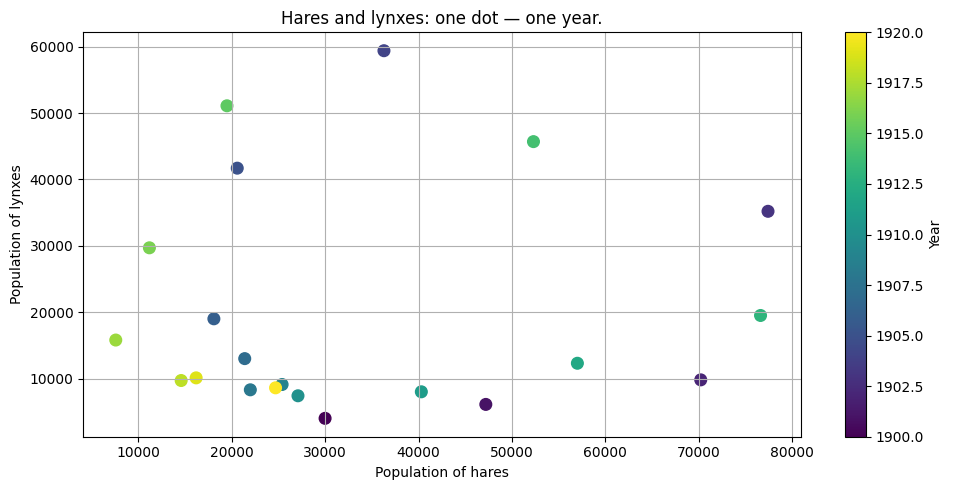

In [11]:
fig, ax = plt.subplots()
points = ax.scatter(populations[:, 0], populations[:, 1], c=years, cmap='viridis', s=70)
fig.colorbar(points, ax=ax, label='Year')
ax.set(xlabel='Population of hares', ylabel='Population of lynxes', title='Hares and lynxes: one dot — one year.')
plt.tight_layout()
plt.show()

Assume the population of hares in 1920 is unknown. Suggest a way to estimate this value. Compare an estimated value
with the true value and print a ratio of the error to the true value.

In [12]:
known = data[data[:, 0] < 1920]
last_two = known[-2:, :2]
estimate = last_two[-1, 1] + np.diff(last_two[:, 1])[0] / np.diff(last_two[:, 0])[0] * (1920 - last_two[-1, 0])
true_value = data[data[:, 0] == 1920, 1].item()
relative_error = abs(estimate - true_value) / true_value
print(f'Estimation of the hare population in 1920: {estimate:.0f}')
print(f'True value: {true_value:.0f}')
print(f'Relative absolute error: {relative_error:.4f} ({relative_error:.2%})')
print('This is a simple assessment: the local linear trend does not take into account the cyclical nature of the population..')

Estimation of the hare population in 1920: 17800
True value: 24700
Relative absolute error: 0.2794 (27.94%)
This is a simple assessment: the local linear trend does not take into account the cyclical nature of the population..


### Let's practice: k-means clustering

<img src="https://media.geeksforgeeks.org/wp-content/uploads/20250103121010720223/Kmeans-implementation.png" width="800"/>

Входные данные в алгоритм: выборка, число кластеров, критерий остановки

Описание алгоритма:
* задаем начальное положение центров кластеров
* пока не выполнен критерий остановки:
  * распределяем точки к ближайшему центру
  * пересчитываем положения центров кластеров как центры масс образовавшихся кластеров

В качестве критерия остановки можно использовать малось изменения суммарной внутрикластерной дисперсии (суммы квадратов расстояний от каждой точки до центра ее кластера) и количество итераций.

### Датасет MNIST

Датасет MNSIT содержит примеры рукописных цифр. Загрузим датасет и посмотрим на примеры

In [ ]:
from pathlib import Path
from sklearn.datasets import fetch_openml

# Локальный кеш необязателен; при его отсутствии загружается исходный MNIST.
cache = Path('mnist_data.npz')
if cache.exists():
    with np.load(cache, allow_pickle=False) as saved:
        images, labels = saved['images'], saved['labels']
else:
    images, labels = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
images = images.astype(np.float32)
labels = labels.astype(str)

```images``` - массив картинок размера 28х28, вытянутых в вектор размера 784. Всего в датасете 70К примеров картинок

In [ ]:
images.shape

(70000, 784)

```labels``` - массив, в котором записано, какая цифра нарисована на каждой картинке картинке

In [ ]:
labels.shape

(70000,)

Нарисуем пример одной из картинок:

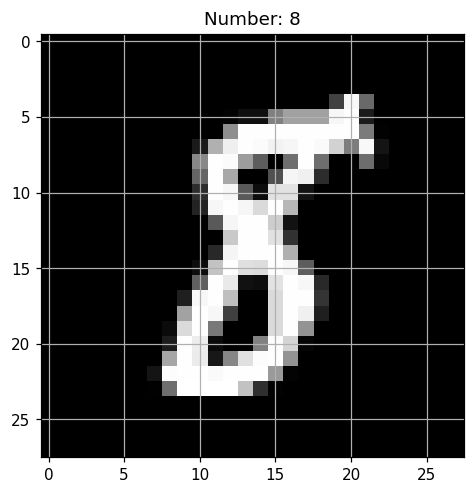

In [ ]:
i = 125
plt.imshow(images[i].reshape(28, 28), cmap='Greys_r')
plt.title('Number: ' + labels[i])
plt.show()

Задание:

1) напишите функцию, реализующую алгоритм k-means.

Входом в функцию является

* массив NxM, где N -- число объектов, M -- число признаков объекта
* k -- число кластеров
* max_iter -- максимальное число итераций
* threshold -- критерий остановки (если на очередной итерации метода суммарное квадратичное отклонение изменяется меньше, чем на threshold, итерации прекращаются)

Выход:

* массив длины N, содержащий индексы кластеров от 0 до k-1
* суммарное квадратичное отклонение для полученного разбиения на кластеры

Постарайтесь обойтись минимальным количеством циклов в вашем коде.

2) Выделите 10 кластеров в датасете MNIST. Дайте интерпретацию каждому полученному кластеру (к какой цифре его можно отнести). Нарисуйте изображения, которые отвечают центрам кластеров. Посчитайте, сколько из точек кластера действительно являются той цифрой, к которой вы его отнесли (для этого сравните с массивом правильных ответов labels) и нарисуйте матрицу ошибок.

In [ ]:
from scipy.sparse import csr_matrix


def k_means(X, k, max_iter=100, threshold=1e-4, random_state=42):
    """Алгоритм Ллойда; возвращает метки и сумму квадратов расстояний.

    threshold — абсолютное изменение суммы квадратов между итерациями.
    Инициализация k-means++; вычисления расстояний и центров векторизованы.
    """
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or not X.size or not np.isfinite(X).all():
        raise ValueError('X должен быть непустой конечной двумерной матрицей')
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= len(X):
        raise ValueError('Необходимо 1 <= k <= N')
    if not isinstance(max_iter, (int, np.integer)) or max_iter < 1 or threshold < 0:
        raise ValueError('max_iter >= 1, threshold >= 0')
    rng = np.random.default_rng(random_state)
    n = len(X)
    norms = np.einsum('ij,ij->i', X, X)
    centers = np.empty((k, X.shape[1]), dtype=X.dtype)
    centers[0] = X[rng.integers(n)]
    closest = np.sum((X - centers[0]) ** 2, axis=1)
    for j in range(1, k):
        total = closest.sum()
        index = rng.choice(n, p=closest / total) if total > 0 else rng.integers(n)
        centers[j] = X[index]
        closest = np.minimum(closest, np.sum((X - centers[j]) ** 2, axis=1))
    previous = np.inf
    for iteration in range(max_iter):
        distances = np.maximum(norms[:, None] + np.sum(centers ** 2, axis=1) - 2 * X @ centers.T, 0)
        assignments = distances.argmin(axis=1)
        counts = np.bincount(assignments, minlength=k)
        membership = csr_matrix((np.ones(n), (assignments, np.arange(n))), shape=(k, n))
        sums = membership @ X
        new_centers = sums / np.maximum(counts[:, None], 1)
        # Пустые кластеры сохраняют прежний центр, поэтому деления на ноль нет.
        centers = np.where(counts[:, None] > 0, new_centers, centers)
        inertia = float(np.sum((X - centers[assignments]) ** 2))
        if abs(previous - inertia) < threshold:
            break
        previous = inertia
    # Метки должны отвечать ближайшим центрам и при остановке по max_iter.
    distances = np.maximum(norms[:, None] + np.sum(centers ** 2, axis=1) - 2 * X @ centers.T, 0)
    assignments = distances.argmin(axis=1)
    final_counts = np.bincount(assignments, minlength=k)
    final_membership = csr_matrix((np.ones(n), (assignments, np.arange(n))), shape=(k, n))
    final_centers = (final_membership @ X) / np.maximum(final_counts[:, None], 1)
    inertia = float(np.sum((X - final_centers[assignments]) ** 2))
    return assignments, inertia


# Проверки на простой выборке и на совпадающих точках.
test_X = np.array([[0., 0.], [0., 2.], [10., 10.], [10., 12.]])
test_clusters, test_inertia = k_means(test_X, 2)
assert test_clusters[0] == test_clusters[1]
assert test_clusters[2] == test_clusters[3]
assert test_clusters[0] != test_clusters[2]
assert np.isclose(test_inertia, 4)
assert np.isclose(k_means(np.ones((5, 2)), 3)[1], 0)
print('Проверки k-means пройдены.')

Проверки k-means пройдены.


### Кластеризация полного MNIST
Используем все 70 000 изображений и все 784 признака. Значения пикселей делим на 255. Метки цифр не участвуют в кластеризации: они нужны только для интерпретации и оценки результата. Каждому кластеру присваивается наиболее частая в нём цифра; несколько кластеров могут соответствовать одной цифре.

Изображений: 70000, признаков: 784
Суммарное квадратичное отклонение: 2753094.24
Кластер | Цифра | Размер | Совпадений | Доля совпадений
      0 |     1 |  12097 |       7720 | 63.82%
      1 |     2 |   5558 |       4912 | 88.38%
      2 |     8 |   7479 |       3972 | 53.11%
      3 |     0 |   3663 |       2982 | 81.41%
      4 |     9 |   8453 |       2920 | 34.54%
      5 |     3 |   8944 |       4734 | 52.93%
      6 |     7 |   7777 |       3171 | 40.77%
      7 |     0 |   3494 |       3166 | 90.61%
      8 |     6 |   6272 |       5412 | 86.29%
      9 |     4 |   6263 |       2655 | 42.39%
Общая доля совпадений после интерпретации: 59.49%


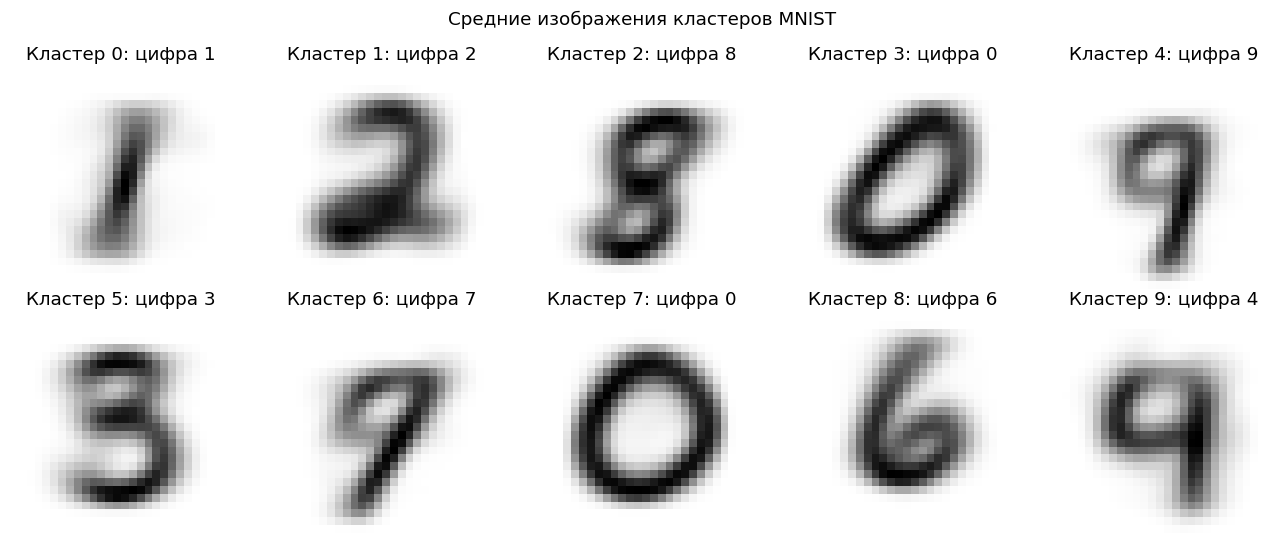

In [ ]:
X = images / 255.0
cluster_ids, inertia = k_means(X, k=10, max_iter=60, threshold=1.0, random_state=42)
true_digits = labels.astype(int)
cluster_sizes = np.bincount(cluster_ids, minlength=10)
cluster_digit_counts = np.zeros((10, 10), dtype=int)
np.add.at(cluster_digit_counts, (cluster_ids, true_digits), 1)
cluster_digits = cluster_digit_counts.argmax(axis=1)
correct_counts = cluster_digit_counts[np.arange(10), cluster_digits]
centers = (csr_matrix((np.ones(len(X)), (cluster_ids, np.arange(len(X)))), shape=(10, len(X))) @ X) / np.maximum(cluster_sizes[:, None], 1)
predicted_digits = cluster_digits[cluster_ids]
print(f'Изображений: {len(X)}, признаков: {X.shape[1]}')
print(f'Суммарное квадратичное отклонение: {inertia:.2f}')
print('Кластер | Цифра | Размер | Совпадений | Доля совпадений')
for j in range(10):
    print(f'{j:7d} | {cluster_digits[j]:5d} | {cluster_sizes[j]:6d} | {correct_counts[j]:10d} | {correct_counts[j] / max(cluster_sizes[j], 1):.2%}')
print(f'Общая доля совпадений после интерпретации: {np.mean(predicted_digits == true_digits):.2%}')
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(centers[j].reshape(28, 28), cmap='gray_r')
    ax.set_title(f'Кластер {j}: цифра {cluster_digits[j]}')
    ax.axis('off')
fig.suptitle('Средние изображения кластеров MNIST')
plt.tight_layout()
plt.show()

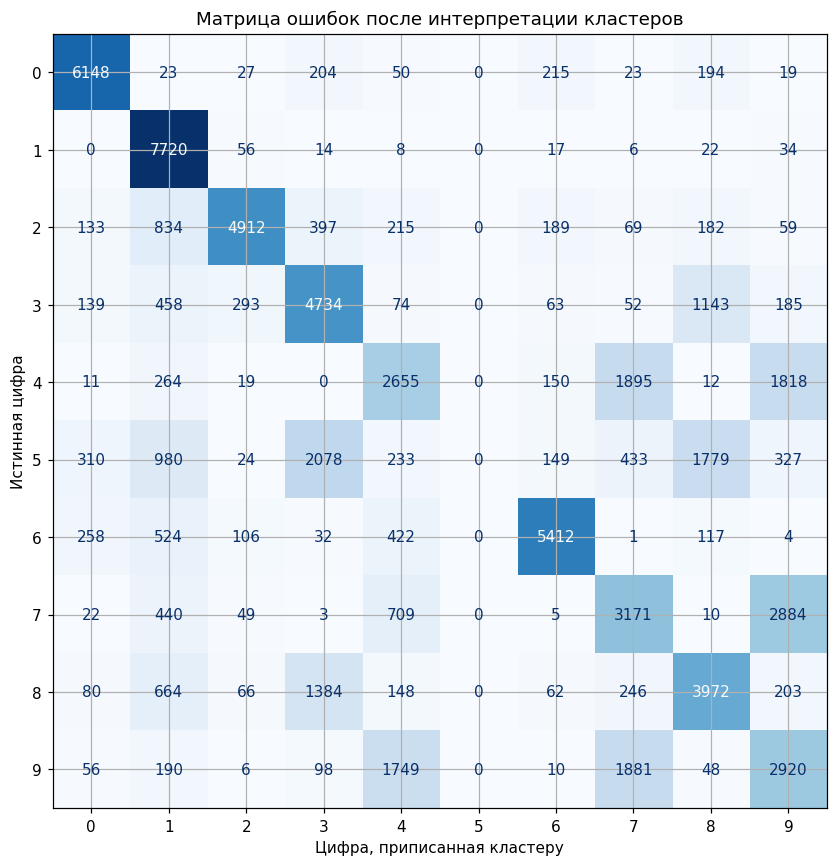

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(true_digits, predicted_digits, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set(xlabel='Цифра, приписанная кластеру', ylabel='Истинная цифра', title='Матрица ошибок после интерпретации кластеров')
plt.tight_layout()
plt.show()
assert cm.sum() == len(images)
assert np.array_equal(cm.diagonal().sum(), correct_counts.sum())

**Интерпретация.** Таблица показывает преобладающую цифру, размер и чистоту каждого кластера, изображения центров — характерное начертание цифр. Похожие начертания разных цифр могут смешиваться, а разные варианты одной цифры — попадать в разные кластеры. Поэтому k-means с 10 кластерами не гарантирует соответствие «один кластер — одна цифра». Оценка получена на той же выборке, по которой определялись преобладающие цифры; это описательная оценка кластеризации, а не точность классификатора на независимой тестовой выборке.